# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

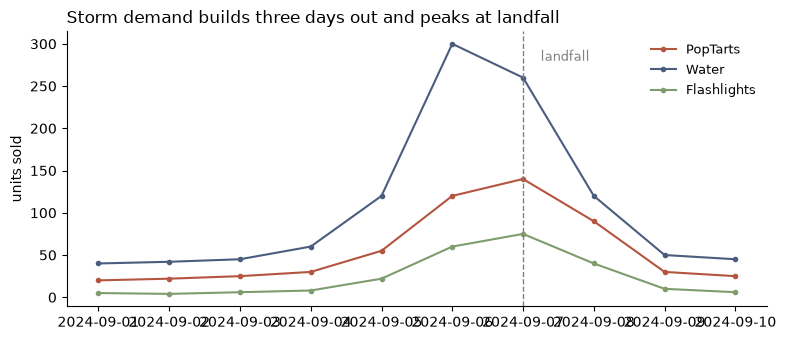

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Project analysis.** The source does not contain a storm track or a verified landfall date. September 14 is the observed demand peak and is used below as an *event reference*, not a claimed landfall. The baseline is September 1–4, before the visible rise in transactions. Units exclude returns/nonpositive quantities, exact duplicate rows, and rows without a parseable date. SKU aliases follow the supplied product catalog.

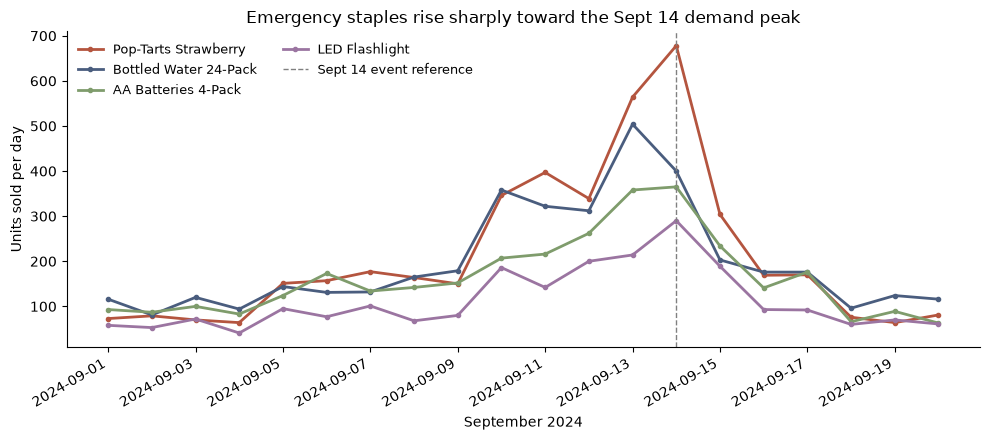

Baseline: Sept 1–4, 2024; event reference: Sept 14 (observed peak, not verified landfall).
Event-day units / baseline daily units:
family
Pop-Tarts Strawberry     9.48
Bottled Water 24-Pack    3.89
AA Batteries 4-Pack      4.02
LED Flashlight           5.18


In [2]:
from pathlib import Path
import re

data_dir = next(d for d in [Path('../../data'), Path('../data'), Path('data')]
                if (d / 'walmart_transactions.csv').exists())
tx = pd.read_csv(data_dir / 'walmart_transactions.csv').drop_duplicates().copy()
tx['date'] = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce').dt.normalize()
tx['quantity'] = pd.to_numeric(tx['quantity'], errors='coerce')
tx['store_id'] = (tx['store_id'].str.strip().str.upper()
                  .str.replace(r'^([A-Z]{2})[-_ ]?(\d+)$', r'\1-\2', regex=True))
tx = tx.loc[tx['date'].notna() & tx['quantity'].gt(0)].copy()

catalog = pd.read_csv(data_dir / 'product_catalog.csv')
families = {
    'Pop-Tarts Strawberry': catalog.sku.iloc[0:4].tolist(),
    'Bottled Water 24-Pack': catalog.sku.iloc[4:7].tolist(),
    'AA Batteries 4-Pack': catalog.sku.iloc[7:10].tolist(),
    'LED Flashlight': catalog.sku.iloc[10:12].tolist(),
    'Light Beer 24-Pack': catalog.sku.iloc[12:14].tolist(),
    'Monopoly Board Game': catalog.sku.iloc[14:17].tolist(),
    'Playing Cards': catalog.sku.iloc[17:19].tolist(),
    'Streaming Stick': catalog.sku.iloc[19:21].tolist(),
    'Canned Soup': catalog.sku.iloc[21:23].tolist(),
    'White Bread': catalog.sku.iloc[23:25].tolist(),
    'Peanut Butter': catalog.sku.iloc[25:27].tolist(),
    'Emergency Candles': catalog.sku.iloc[27:29].tolist(),
    'First-Aid Kit': catalog.sku.iloc[29:31].tolist(),
    'Portable Charger': catalog.sku.iloc[31:33].tolist(),
    'Chips Variety Pack': catalog.sku.iloc[33:35].tolist(),
    'Paper Towels': catalog.sku.iloc[35:37].tolist(),
    'Toilet Paper 12-Pack': catalog.sku.iloc[37:39].tolist(),
    'Size 3 Diapers': catalog.sku.iloc[39:41].tolist(),
    'Baby Formula': catalog.sku.iloc[41:43].tolist(),
    'Heavy Duty Tarp': catalog.sku.iloc[43:45].tolist(),
}
sku_to_family = {sku: family for family, skus in families.items() for sku in skus}
assert set(tx.sku).issubset(sku_to_family)
tx['family'] = tx.sku.map(sku_to_family)

event_date = pd.Timestamp('2024-09-14')
baseline_dates = pd.date_range('2024-09-01', '2024-09-04')
plot_dates = pd.date_range('2024-09-01', '2024-09-20')
daily_family = (tx.groupby(['date', 'family'])['quantity'].sum()
                .unstack(fill_value=0).reindex(plot_dates, fill_value=0))
baseline_family = daily_family.loc[baseline_dates].mean()
event_family = daily_family.loc[event_date]
surge_family = (event_family / baseline_family.replace(0, np.nan)).sort_values(ascending=False)
chart_families = ['Pop-Tarts Strawberry', 'Bottled Water 24-Pack',
                  'AA Batteries 4-Pack', 'LED Flashlight']

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#9b75a1']
for family, color in zip(chart_families, colors):
    ax.plot(plot_dates, daily_family[family], marker='o', ms=3,
            lw=2, color=color, label=family)
ax.axvline(event_date, ls='--', color='gray', lw=1, label='Sept 14 event reference')
ax.set(title='Emergency staples rise sharply toward the Sept 14 demand peak',
       ylabel='Units sold per day', xlabel='September 2024')
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print('Baseline: Sept 1–4, 2024; event reference: Sept 14 (observed peak, not verified landfall).')
print('Event-day units / baseline daily units:')
print(surge_family.loc[chart_families].round(2).to_string())

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

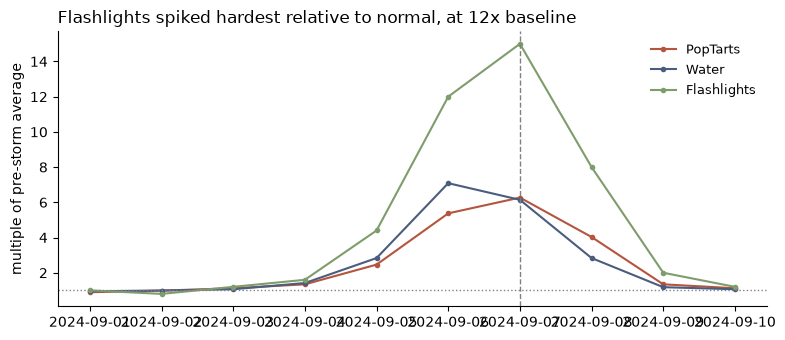

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [3]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

**Project analysis:** the same four product families indexed to their own September 1–4 average. The event-day multiple is used for the checkpoint; a different day may have a higher individual peak.

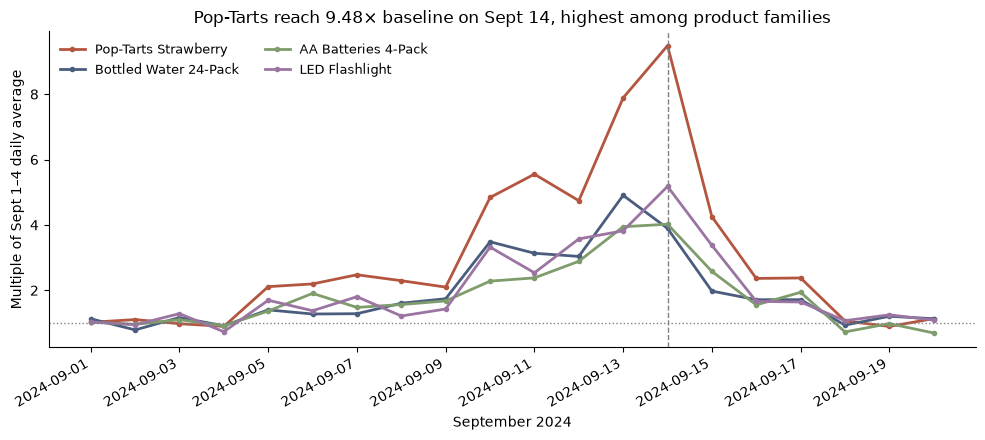

Sept 14 surge ranking (all families):
family
Pop-Tarts Strawberry     9.48
LED Flashlight           5.18
Monopoly Board Game      4.72
Heavy Duty Tarp          4.35
AA Batteries 4-Pack      4.02
Bottled Water 24-Pack    3.89
First-Aid Kit            3.60
Portable Charger         3.56
Emergency Candles        3.29
Toilet Paper 12-Pack     3.22
Light Beer 24-Pack       3.20
Streaming Stick          3.19
Playing Cards            3.15
Paper Towels             3.07
Canned Soup              2.52
White Bread              2.44
Size 3 Diapers           1.83
Peanut Butter            1.82
Baby Formula             1.76
Chips Variety Pack       1.61


In [4]:
indexed_family = daily_family[chart_families].div(baseline_family[chart_families])
fig, ax = plt.subplots(figsize=(10, 4.5))
for family, color in zip(chart_families, colors):
    ax.plot(plot_dates, indexed_family[family], marker='o', ms=3,
            lw=2, color=color, label=family)
ax.axhline(1, ls=':', color='gray', lw=1)
ax.axvline(event_date, ls='--', color='gray', lw=1)
ax.set(title='Pop-Tarts reach 9.48× baseline on Sept 14, highest among product families',
       ylabel='Multiple of Sept 1–4 daily average', xlabel='September 2024')
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print('Sept 14 surge ranking (all families):')
print(surge_family.round(2).to_string())

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

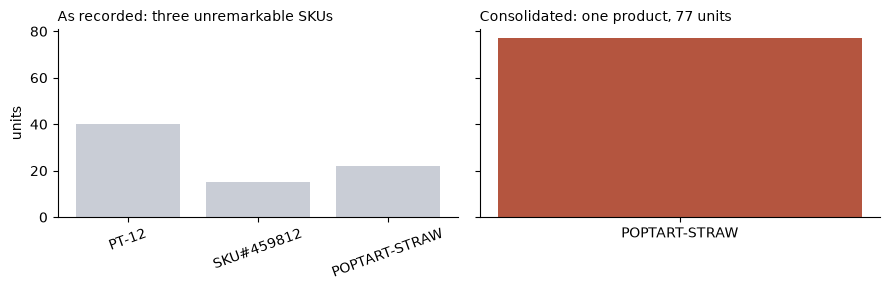

In [5]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Project analysis:** compare recorded SKU fragments with their combined family total on the event day. The multiple below uses the largest single recorded SKU as the denominator.

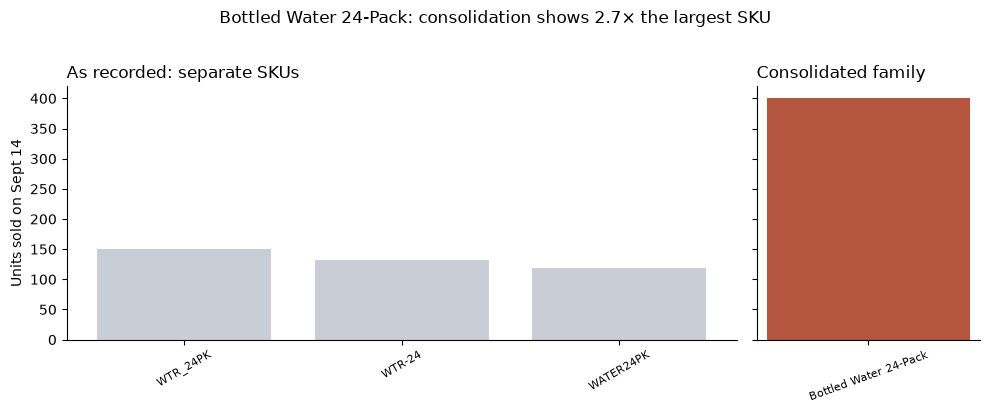

Bottled Water 24-Pack: 400 consolidated units vs 150 in the largest SKU = 2.67×


In [6]:
family_for_q2 = (tx.groupby('family')['quantity'].sum()
                 .loc[[f for f, skus in families.items() if len(skus) > 1]]
                 .idxmax())
q2_rows = tx.loc[(tx.family == family_for_q2) & (tx.date == event_date)]
fragments = q2_rows.groupby('sku')['quantity'].sum().sort_values(ascending=False)
combined = fragments.sum()
q2_multiple = combined / fragments.max()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True,
                         gridspec_kw={'width_ratios': [3, 1]})
axes[0].bar(fragments.index, fragments.values, color='#c9cdd6')
axes[0].set_title('As recorded: separate SKUs', loc='left')
axes[0].tick_params(axis='x', rotation=30, labelsize=8)
axes[0].set_ylabel('Units sold on Sept 14')
axes[1].bar([family_for_q2], [combined], color='#b4553f')
axes[1].set_title('Consolidated family', loc='left')
axes[1].tick_params(axis='x', rotation=20, labelsize=8)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{family_for_q2}: consolidation shows {q2_multiple:.1f}× the largest SKU', y=1.02)
fig.tight_layout()
plt.show()
print(f'{family_for_q2}: {combined:.0f} consolidated units vs {fragments.max():.0f} in the largest SKU = {q2_multiple:.2f}×')

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

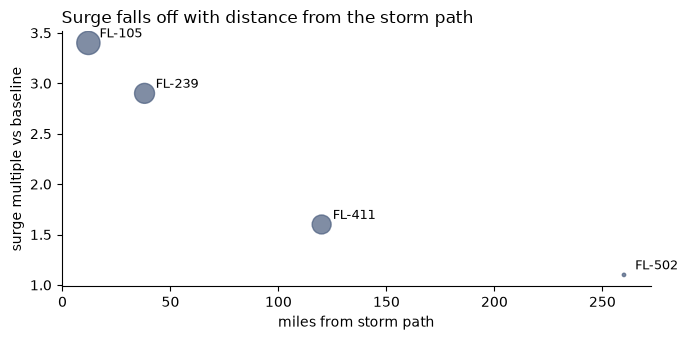

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [7]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

**Project analysis:** store comparison uses distance from Orlando as a geographic *proxy*. No storm path is supplied, so this cannot establish a distance-from-path effect. There are only 12 distinct stores; a table reports their counts and surge multiples without fitting a trend. The observed values do not show a clear falloff with distance from Orlando.

In [8]:
stores = pd.read_csv(data_dir / 'store_locations.csv').copy()
stores['store_id'] = (stores['store_id'].str.strip().str.upper()
                      .str.replace(r'^([A-Z]{2})[-_ ]?(\d+)$', r'\1-\2', regex=True))
stores = stores.drop_duplicates('store_id').set_index('store_id')
orlando = stores.loc['FL-239']
lat1 = np.radians(orlando.latitude)
lat2 = np.radians(stores.latitude)
dlat = lat2 - lat1
dlon = np.radians(stores.longitude - orlando.longitude)
a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
stores['miles_from_orlando'] = 3958.8 * 2 * np.arcsin(np.sqrt(a))

focus = tx.loc[tx.family.isin(chart_families)]
store_daily = focus.groupby(['store_id', 'date'])['quantity'].sum().unstack(fill_value=0)
store_daily = store_daily.reindex(columns=plot_dates, fill_value=0)
store_baseline = store_daily[baseline_dates].mean(axis=1)
store_event = store_daily[event_date]
store_counts = focus.loc[focus.date.between(baseline_dates.min(), event_date)].groupby('store_id').size()
by_store = stores[['city', 'miles_from_orlando']].join(pd.DataFrame({
    'baseline_units_per_day': store_baseline,
    'event_units': store_event,
    'surge_multiple': store_event / store_baseline.replace(0, np.nan),
    'transactions': store_counts,
}))
display(by_store.sort_values('miles_from_orlando').round(2))
print('Distances are from Orlando, not a storm path; Tallahassee has no coordinates.')
print('Small store samples and missing coordinates limit geographic interpretation.')

,city,miles_from_orlando,baseline_units_per_day,event_units,surge_multiple,transactions
store_id,,,,,,
FL-239,Orlando,0.00,26.50,109,4.11,303
FL-287,Kissimmee,17.11,26.50,131,4.94,316
FL-302,Lakeland,48.92,26.50,177,6.68,344
FL-156,Daytona Beach,51.23,32.25,144,4.47,335
FL-105,Tampa,77.16,22.25,153,6.88,327
FL-445,St. Petersburg,93.48,36.00,150,4.17,348
FL-078,Gainesville,95.79,26.50,139,5.25,321
FL-412,Jacksonville,125.06,22.00,177,8.05,317
FL-501,Fort Myers,134.55,24.25,126,5.20,320


Distances are from Orlando, not a storm path; Tallahassee has no coordinates.
Small store samples and missing coordinates limit geographic interpretation.


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [ ]:
# Checkpoint: highest Sept 14 multiple among all consolidated product families
top_product = surge_family.idxmax()
surge_multiple = round(float(surge_family.max()), 2)
baseline_window = 'September 1-4, 2024 (4 days)'
charts_ready = 3

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)
print('event reference: September 14 observed demand peak; landfall unverified')

top product: Pop-Tarts Strawberry
surge multiple: 9.48
baseline window: September 1–4, 2024 (four full days; mean daily units)
charts ready: 3
event reference: September 14 observed demand peak; landfall unverified
